# 04 · Thin lenses, phase curvature, and focus

A thin lens changes phase across a field. Combining that phase with propagation produces a focus; the thin-lens equation gives a geometric prediction for its location.

This is the package-user version: imports come first, and each operation is introduced when the physical question calls for it.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from topolino import propTF, gaussian, rms_width


## 1. Define the lens as a phase mask

For a paraxial thin lens, the phase is quadratic in transverse position. Multiplying by this complex phase changes curvature without changing the field magnitude at the lens plane.

In [ ]:
lambda_m = 500e-9
window_m = 4e-3
n = 2048
x_m = np.linspace(-window_m/2, window_m/2, n, endpoint=False)
f_m = 0.20
field_in = gaussian(x_m, 0, 250e-6)
lens = np.exp(-1j*np.pi*x_m**2/(lambda_m*f_m))
field_after_lens = field_in*lens


## 2. Propagate and locate the focus

The field is propagated from the lens plane over a range of distances. The smallest RMS width estimates the focus in this simulation.

In [ ]:
z_values_m = np.linspace(0.16, 0.24, 41)
widths_m = np.array([rms_width(propTF(field_after_lens, window_m, lambda_m, z), x_m) for z in z_values_m])


## 3. Compare with the thin-lens equation

For an object plane a distance `p_m` before the lens, the image distance satisfies `1/f = 1/p + 1/q`. This ideal geometric estimate is useful alongside the wave simulation.

In [ ]:
p_m = 0.50
q_m = 1/(1/f_m - 1/p_m)
print(f"Thin-lens image distance: {q_m:.3f} m")


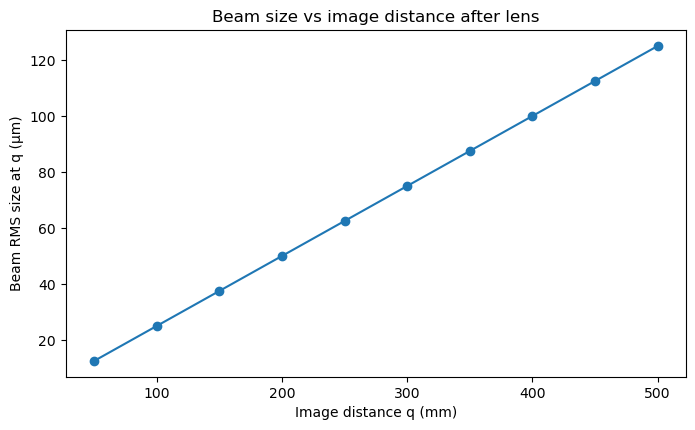

In [20]:


plt.figure(figsize=(8, 4.5))
plt.plot(q_m_list*1e3, beam_sizes, 'o-')
plt.xlabel("Image distance q (mm)")
plt.ylabel("Beam RMS size at q (µm)")
plt.title("Beam size vs image distance after lens")
plt.show()


From `paper/tilt.ipynb`, cell 9.


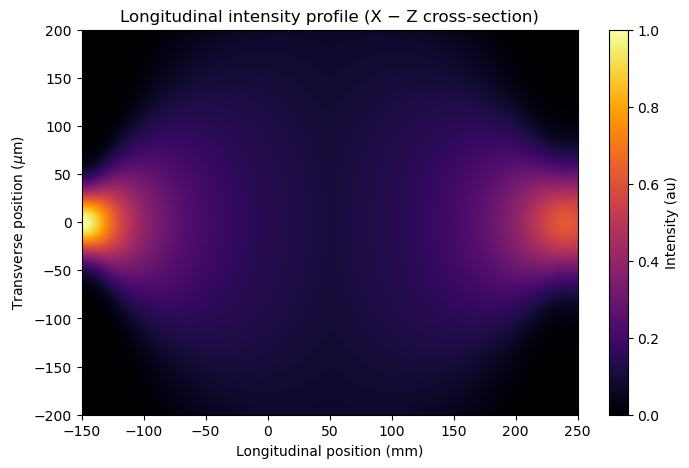

In [28]:
plt.figure(figsize=(8, 5))
plt.imshow(np.transpose(I_zx),
           extent=[z_all[0]*1e3, z_all[-1]*1e3, x_m[0]*1e6, x_m[-1]*1e6],
           aspect='auto',
           cmap='inferno')
plt.colorbar(label="Intensity (au)")
plt.ylim([-200, 200])  # Updated bounds in micrometers (-0.0002 m to 0.0002 m)
plt.xlabel("Longitudinal position (mm)")
plt.ylabel("Transverse position ($\mu$m)")
plt.xlim([-150, 250])
plt.title('Longitudinal intensity profile (X − Z cross-section)')
plt.show()